# From population activity to a tone the mouse can hear

What the closed loop actually computes, and what each stage of it means.

```
  neurons  ──►  M = Wᵀx  ──►  CS = M/‖M‖  ──►  D = |CS|^p · M  ──►  tone (Hz)  ──►  speaker
  (spks)        projection     angle in        the cursor          exponential     gated by
                onto each      factor space    the animal          in D/θ          soundVolume
                factor                         controls
```

### The one thing to take away

**The cursor is not a projection.** `D = |CS|^p · M` with `p = 2` collapses to
`D = M³/‖M‖²`, which is cubic-over-quadratic. Its level sets in the plane spanned by
"the decoder axis" and "everything else" are **not** lines parallel to the off-axis
direction — they curve away, so an animal whose activity is not aligned with the axis
needs a *larger* projection to reach the same cursor value. Section 2 draws exactly that.

### What is exact here and what is not

| quantity | source | status |
|---|---|---|
| `D` (= `cursor_brain`), `CS` (= `decoder_angles`), the tone, the task flags | the rig's own logger | **exact** |
| `M` and `‖M⊥‖` | recovered as `M = D/\|CS\|^p`, `‖M⊥‖ = \|M\|·√(1/CS²−1)` | **exact** — round-trips to 9e-16 |
| the neuron panel of §3.1 only | packet `spks`, z-scored and causally smoothed | **illustrative** — see §3 |

Every geometric claim below is the rig's own arithmetic, not a reconstruction. The one
panel that shows neurons is display only; nothing downstream of it depends on that panel.

### Assumptions and caveats

* `cursor_factor_to_use` is **MATLAB 1-indexed**; the python column is its value − 1.
  On remapping days it changes **within** a session, so `cursor_brain` is not one axis there.
* **Read the reward threshold from the `timeSeries` column, not from `expParams.params`** —
  `params.cursor.threshold_reward` is stale (1.5) where the live column says 1.9 or 6.0.
* `|CS|` is defined over the **K decoder factors only**, not the whole neural space. It
  measures exclusivity among the decoder's own axes.
* The `M`/`‖M⊥‖` recovery divides by `|CS|^p`, so frames with `|CS| < CS_FLOOR` are dropped
  rather than clipped (≈ 22 % of frames on the example day). They are near the origin, where
  the cursor is tiny and the geometry is ill-conditioned anyway.
* **`cursor_output`, not `cursor_brain`, is what the speaker and the reward test follow.**
  They agree on 93 % of in-experiment frames; §3.1 draws the difference wherever it occurs.
* **`CE_experimentRunning` is an umbrella flag, not an epoch.** The 15 % of frames outside it
  are before and after the session, where the tone is NaN; §2.2 excludes them.
* **The quiescence gate is `M ≤ 0`, not the `0.1·θ` the parameter name suggests** — §3.3.
* `soundVolume` is **binary**, a gate rather than a level, and the packet has no speaker
  calibration. There is therefore no dB-SPL axis anywhere in this notebook; the perceptual
  axis used is **octaves** (`log2 Hz`), which is exact.
* During reward the tone is overridden to a constant, so those samples are not cursor
  control. They are drawn in the reward colour throughout.

### Using it

The setup cell carries every knob: `THEME` (light/dark), `FONT_SCALE`, the mouse and day,
and the window that every time-series figure shows — set **either** `START_MIN` (minutes
into the session) **or** `START_TRIAL` (an index into the true-BMI trial table), with
`WIN_SEC` for the length. Setting both raises rather than silently picking one.

This notebook has **no builder**: edit the `.ipynb` directly, and nothing will regenerate
over the top of it.

### Colour

One colour family per figure. In §2 colour is the cursor value itself, on a 0 → 1 scale
where 1 is reward; in the time-series figures colour marks the **task state** (orange
quiescence, grey trial, green reward tone) while every data trace is black, and thresholds
carry the colour of the state they gate.

## 1 · Setup

In [2]:
%matplotlib inline
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from scipy.signal import lfilter

# ---- find the notebook dir whether we run from here or from the repo root ----
NB_DIR = Path.cwd() if (Path.cwd() / "_style.py").exists() else Path.cwd() / "wrapup_notebooks"
sys.path.insert(0, str(NB_DIR))
import _style as st
import _draw as dw
import importlib; importlib.reload(st); importlib.reload(dw)

REPO = st.repo_root()
sys.path.insert(0, str(REPO / "utilities"))
import neural_analysis_utils as na
import cursor_analysis_utils as ca
import richfile as rfs
na.register_richfile_types(rfs)

# ================= SETTINGS =================
THEME       = "dark"         # "light" | "dark"  -> restyles every figure below
FONT_SCALE  = 1.0            # multiplies every font size at once
MOUSE       = "mouse_0403L"
DAY_INDEX   = 8              # index into the mouse's day list (a mid stable day)
REMAP_DAY_I = 22             # a remapping day, for the two-pitch-scales panel
DATA_ROOT   = Path(r"C:\Data\datasets\bmi_packets\bmi_packets")
SR          = 30.0           # imaging / logger frame rate
CS_FLOOR    = 0.05           # drop frames where |CS| is too small to invert the gate

# ---- which slice of the session every time-series figure shows ----
# Set exactly ONE of these; the other stays None. Setting both raises.
START_MIN   = 5           # minutes into the session, e.g. 14.5
START_TRIAL = 20             # trial index into the true-BMI table, 0 .. n_trials-1
WIN_SEC     = 60.0           # window length in seconds (keep >= 60 for the talk)
# ============================================

P = st.init(notebook="01_decoder_and_cursor", theme=THEME, scale=FONT_SCALE)

# Two ramps, two jobs.
#   FIELD_CMAP  the value of a scalar field -- here the cursor itself, so it earns a real
#               perceptual colormap and a 0 -> 1 scale where 1 is the reward threshold.
#   INK_CMAP    "amount of ink": 2-D histogram density and the neuron heatmap. Those are
#               counts and activity, not the cursor, so they stay monochrome and theme-aware.
FIELD_CMAP = st.SEQ_CMAP
INK_CMAP = LinearSegmentedColormap.from_list("ink", [P["bg"], P["fg"]])

theme=dark  scale=1  figures -> output\wrapup_notebooks\01_decoder_and_cursor


## 2 · The decoder, exactly as the rig computed it

`decoder_angles` in the logger **is** `CS` for the active factor, and `cursor_brain_raw`
**is** `D`. Both are logged per frame, so the projection can be inverted rather than
re-estimated:

$$M = \frac{D}{|CS|^{p}}, \qquad \lVert M\rVert = \frac{M}{CS}, \qquad
  \lVert M_{\perp}\rVert = |M|\sqrt{\tfrac{1}{CS^{2}}-1}$$

The cell below rebuilds `D` from the recovered `(M, ‖M⊥‖)` and reports the round-trip error
as a check that this is the rig's arithmetic and not an approximation of it.

In [3]:
r = na.open_mouse(rfs, DATA_ROOT, MOUSE)
DAYS = na.get_day_list(r)
DAY = DAYS[DAY_INDEX]

dec = ca.get_decoder_df(r, DAY)
ts  = ca.get_timeseries_df(r, DAY)
NF  = min(len(dec), len(ts))                 # 3 days of 0403L have a truncated logger
dec, ts = dec.iloc[:NF], ts.iloc[:NF]

D   = np.asarray(dec["cursor_brain_raw"], float)
CB  = np.asarray(dec["cursor_brain"], float)   # == D here (win_smooth_cursor = 1)
CO  = np.asarray(dec["cursor_output"], float)  # the record that drives the tone
CS  = np.asarray(dec["decoder_angles"], float)
FRQ = np.asarray(dec["freqToOutput"], float)
POW = float(np.nanmedian(np.asarray(ts["cursor_angle_power"], float)))
THR = float(np.nanmedian(np.asarray(ts["cursor_threshold_reward"], float)))
THR_Q  = float(np.nanmedian(np.asarray(ts["cursor_thresh_quiescence_cursorDecoder"], float)))
THR_QM = float(np.nanmedian(np.asarray(ts["cursor_thresh_quiescence_cursorMag"], float)))

# ---- invert the gate: exact, wherever |CS| is big enough to divide by ----
usable = np.isfinite(D) & np.isfinite(CS) & (np.abs(CS) > CS_FLOOR)
M = np.full(NF, np.nan); MP = np.full(NF, np.nan)
M[usable]  = D[usable] / np.abs(CS[usable]) ** POW
MP[usable] = np.abs(M[usable]) * np.sqrt(np.maximum(1.0 / CS[usable] ** 2 - 1.0, 0.0))

# the angle to the decoder axis needs no inversion, so it is defined on every frame
ANG = np.degrees(np.arccos(np.clip(np.abs(CS), 0.0, 1.0)))   # 0 = on-axis, 90 = all off

# ---- round-trip check ----
D_rt = M ** 3 / (M ** 2 + MP ** 2)
g = np.isfinite(D_rt) & np.isfinite(D)
RT_ERR = float(np.nanmax(np.abs(D_rt[g] - D[g])))

# ---- task flags ----
# CE_trial / CE_ITI_withZ / CE_rewardDelivery / CE_timeout / CE_waitForBaseline are the
# mutually exclusive epochs. CE_experimentRunning is NOT one of them -- it is an umbrella
# flag, and the 15% of frames outside it are before/after the session, where the tone is
# NaN. CS_* are per-frame conditions that can be true inside any epoch.
stage = {k: np.asarray(ts[k], float) > 0.5 for k in
         ["CS_quiescence", "CE_trial", "CS_threshold", "CE_rewardDelivery",
          "CE_ITI_withZ", "CE_timeout", "CE_waitForBaseline", "CE_experimentRunning",
          "frequencyOverride"]}
IN_EXP = stage["CE_experimentRunning"]
VOL = np.asarray(ts["soundVolume"], float)

# ---- where is the population when the animal earns reward? ----
at_thr = np.isfinite(D) & (D >= THR) & usable
M_AT, MP_AT = float(np.nanmedian(M[at_thr])), float(np.nanmedian(MP[at_thr]))

trials = na.get_true_bmi_trials(na.get_trials_df(r, DAY))
par    = r["extras"]["expParams"][DAY]["params"].load()

# ---- the measured cursor -> tone law (section 3.2 fits it; here it is a converter) ----
# It is a law about cursor_output, which is what the speaker follows.
TONE_F0, TONE_SLOPE = 2962.635, 1.5669        # log2 f = log2 F0 + SLOPE * D/theta
d_to_oct = lambda d: np.log2(TONE_F0 / 1000.0) + TONE_SLOPE * (np.asarray(d, float) / THR)
oct_to_d = lambda o: (np.asarray(o, float) - np.log2(TONE_F0 / 1000.0)) / TONE_SLOPE * THR
OCT = np.log2(FRQ / 1000.0)                   # the played tone, in octaves above 1 kHz

# ---- the quiescence gate, as the rig actually tests it ------------------------------
# The documented rule is a conjunction: M <= thresh_quiescence_cursorMag AND
# D <= thresh_quiescence_cursorDecoder. thresh_quiescence_cursorMag is built as
# max(10th percentile of M, 0) and comes out as exactly 0 on every day checked, which
# makes the M term the binding one: D and M always share a sign, so the gate reduces to
# "the cursor is at or below zero" -- a much harder ask than the 0.1*theta that the
# cursorDecoder threshold suggests, and the one the animal actually has to satisfy.
M_sign = np.where(np.abs(CS) > 0, D / np.abs(CS) ** POW, np.nan)   # no floor: sign only
CSQ_PRED = np.nan_to_num(M_sign, nan=np.inf) <= THR_QM
CSQ_PRED &= D <= THR_Q
CSQ_AGREE = float(np.mean(CSQ_PRED == stage["CS_quiescence"]))
# a single horizontal line in cursor units is honest only when the M term is zero
D_QUIESC = 0.0 if THR_QM == 0.0 else None


# ---- the decoder as a function of the two coordinates the maps use ------------------
# D = |CS|^p * M with CS = M/||M||, so in units of theta (m = M/theta, mp = ||M_perp||/theta)
# the SAME formula gives D/theta: the map is scale-free, and the reward level is exactly 1.
def gated_field(x_perp, y_axis, p=POW):
    nrm = np.sqrt(y_axis ** 2 + x_perp ** 2)
    with np.errstate(invalid="ignore", divide="ignore"):
        cs = np.where(nrm > 0, y_axis / nrm, 0.0)
    return np.abs(cs) ** p * y_axis


# ---- one background colour per frame, by priority, so bands never overlap ----------
# CS_quiescence is a per-frame condition that is also true inside trials. Drawing it as a
# band on top of the trial band mixes two translucent colours into a third that means
# nothing, so every frame gets exactly ONE state: later keys win. Everything else gets
# no background at all.
STATE_ORDER = ["quiescence", "trial", "reward tone"]
STATE_SRC   = {"quiescence":  stage["CS_quiescence"],
               "trial":       stage["CE_trial"],
               "reward tone": stage["frequencyOverride"]}
STATE_COL   = {"quiescence": P["baseline"], "trial": P["single"], "reward tone": P["correct"]}
STATE_ALPHA = {"quiescence": 0.22, "trial": 0.40, "reward tone": 0.35}
# CS_quiescence flickers on every zero crossing of the cursor, which over a minute is
# hundreds of 1-2 frame slivers. Only runs that reach duration_quiescenceHold can arm
# a trial, so shorter ones are left unpainted rather than turned into visual noise.
QHOLD = int(par["trial"]["duration_quiescenceHold"])
STATE_MIN   = {"quiescence": QHOLD, "trial": 1, "reward tone": 1}
STATE_LAB   = {"quiescence": rf"quiescence ($\geq${QHOLD} frames)", "trial": "trial",
               "reward tone": "reward tone"}

STATE = np.zeros(NF, int)                      # 0 = no background
for _i, _k in enumerate(STATE_ORDER, start=1):
    STATE[STATE_SRC[_k]] = _i


def paint_states(ax, f0, ref, keys=STATE_ORDER, f1=None):
    """Lay the task state behind an axes already plotted in seconds relative to `ref`."""
    f1 = NF if f1 is None else f1
    for i, k in enumerate(STATE_ORDER, start=1):
        if k in keys:
            dw.span_bands(ax, STATE[f0:f1] == i, color=STATE_COL[k], alpha=STATE_ALPHA[k],
                          sr=SR, t0=ref - f0, zorder=0, min_frames=STATE_MIN[k])


def state_legend(ax, extra=(), keys=STATE_ORDER, **kw):
    ent = [(STATE_LAB[k], "patch", STATE_COL[k], dict(alpha=STATE_ALPHA[k])) for k in keys]
    return dw.legend_from(ax, ent + list(extra), **kw)


# ---- which slice of the session to look at -----------------------------------------
def pick_window(start_min=None, start_trial=None, win_sec=None, pre_sec=3.0):
    """Frame window + the frame that counts as t = 0, from EITHER a session time in
    minutes OR a trial index. Returns (f0, f1, ref, xlabel)."""
    win_sec = WIN_SEC if win_sec is None else win_sec
    if start_min is not None and start_trial is not None:
        raise ValueError("set START_MIN or START_TRIAL, not both")
    n = int(round(win_sec * SR))
    if n > NF:
        raise ValueError(f"win_sec={win_sec:g} is longer than the {NF / SR / 60:.1f} min session")
    if start_min is not None:
        f0 = int(np.clip(round(start_min * 60.0 * SR), 0, NF - n))
        return f0, f0 + n, f0, f"time from {f0 / SR / 60:.1f} min into the session (s)"
    i = 0 if start_trial is None else int(start_trial)
    if not 0 <= i < len(trials):
        raise IndexError(f"trial {i} is outside 0..{len(trials) - 1}")
    ref = int(trials.start[i])
    f0 = int(np.clip(ref - pre_sec * SR, 0, NF - n))
    return f0, f0 + n, ref, f"time from the start of trial {i} (s)"


print(f"{MOUSE}  {DAY}   {NF} frames = {NF / SR / 60:.0f} min   {len(trials)} true-BMI trials")
print(f"p={POW:g}   reward threshold={THR:g}   quiescence thresholds: "
      f"cursorDecoder={THR_Q:g}, cursorMag={THR_QM:g}")
print(f"usable frames (|CS|>{CS_FLOOR}): {usable.mean():.1%}   "
      f"inside CE_experimentRunning: {IN_EXP.mean():.1%}")
print(f"round-trip  max|D_rebuilt - D_logged| = {RT_ERR:.2e}   <- exact, not a fit")
print(f"median |CS| during trials: {np.nanmedian(np.abs(CS[stage['CE_trial']])):.3f}"
      f"  -> only {np.nanmedian(np.abs(CS[stage['CE_trial']]))**POW:.1%} of M reaches the cursor")
print(f"at reward: median M = {M_AT:.2f} and median ||M_perp|| = {MP_AT:.2f}, "
      f"where a perfectly aligned state would need M = {THR:g}  "
      f"(a {M_AT/THR - 1:+.0%} surcharge for being off-axis)")
print(f"quiescence gate: CS_quiescence == (M <= {THR_QM:g}) & (D <= {THR_Q:g}) on "
      f"{CSQ_AGREE:.3%} of frames   -> the binding term is M, i.e. D <= {D_QUIESC}")
print(f"thresholds on the tone axis: quiescence {2 ** d_to_oct(D_QUIESC) * 1000:.0f} Hz, "
      f"reward {2 ** d_to_oct(THR) * 1000:.0f} Hz")

mouse_0403L  20230712   108000 frames = 60 min   257 true-BMI trials
p=2   reward threshold=1.9   quiescence thresholds: cursorDecoder=0.19, cursorMag=0
usable frames (|CS|>0.05): 78.2%   inside CE_experimentRunning: 85.1%
round-trip  max|D_rebuilt - D_logged| = 8.88e-16   <- exact, not a fit
median |CS| during trials: 0.320  -> only 10.2% of M reaches the cursor
at reward: median M = 2.92 and median ||M_perp|| = 1.60, where a perfectly aligned state would need M = 1.9  (a +54% surcharge for being off-axis)
quiescence gate: CS_quiescence == (M <= 0) & (D <= 0.19) on 100.000% of frames   -> the binding term is M, i.e. D <= 0.0
thresholds on the tone axis: quiescence 2963 Hz, reward 8777 Hz


### 2.1 · What the decoding map looks like

Both axes and the cursor are in units of the animal's own reward threshold θ, which the
formula allows exactly: `D = M³/‖M‖²` is homogeneous of degree 1, so dividing `M` and
`‖M⊥‖` by θ divides `D` by θ as well. **The colour scale therefore runs 0 → 1, and 1 is
reward** — on any animal, on any day.

`x` is how much population activity sits on the **other** decoder factors, `y` is how much
sits on **this** one.

* **a** — a pure projection. Contours are horizontal: off-axis activity is irrelevant, and
  reward is a fixed amount of on-axis activity.
* **b** — what the rig actually computes. The contours bend upward, so the same cursor value
  costs more on-axis activity the further off-axis the animal is.
* **c** — that cost, on its own: the fraction of `M` the gate lets through, against angle.

saved fig1_decoding_map.pdf, fig1_decoding_map.png


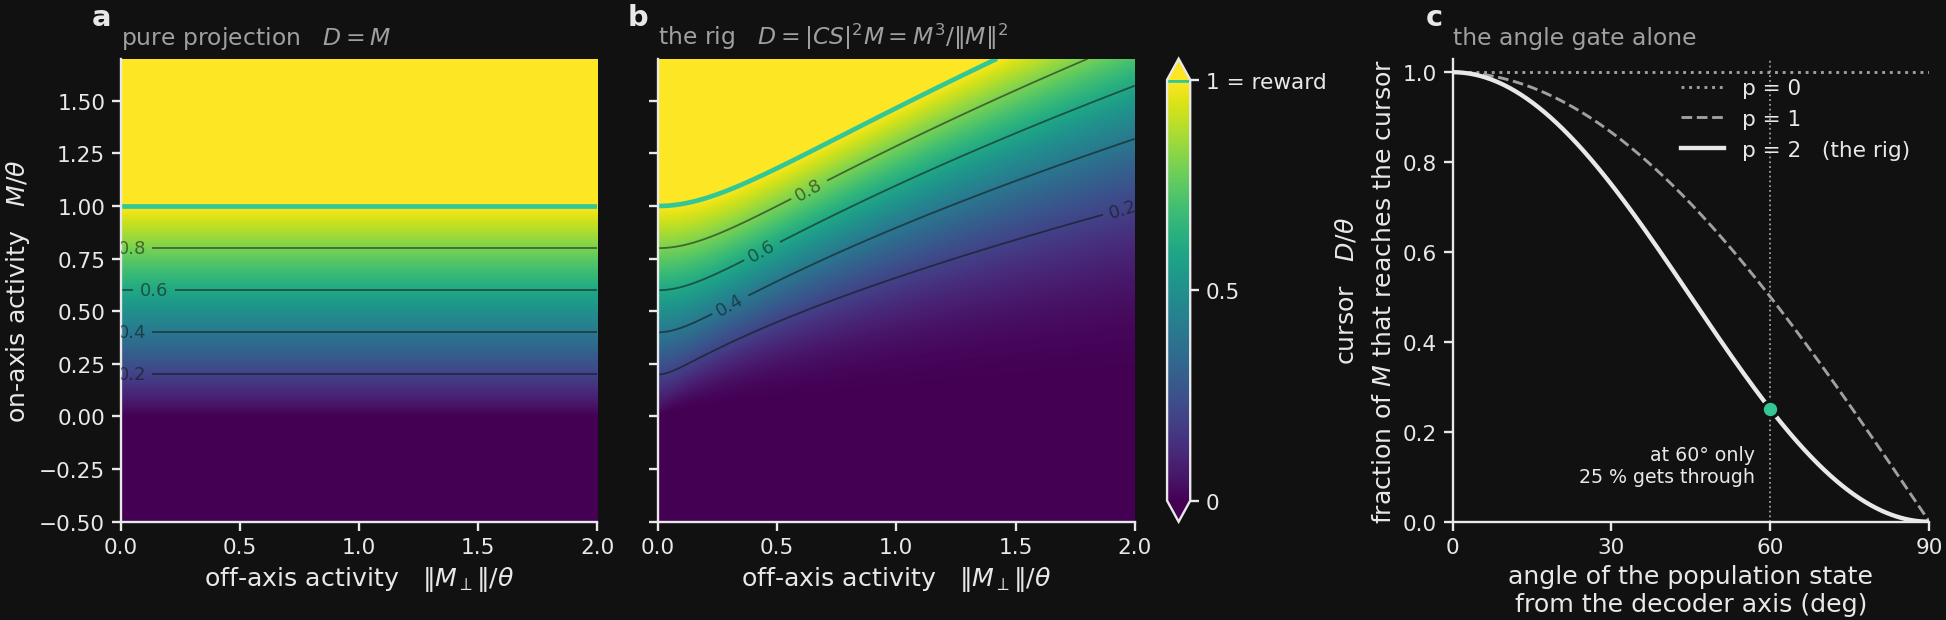

In [13]:
# ===== SETTINGS =====
FIGSIZE  = (15.0, 4.8)
X_MAX    = 2.5                       # ||M_perp|| / theta
Y_LIM    = (-0.5, 2.5)               # M / theta
GRID_N   = 600
LEVELS   = [0.2, 0.4, 0.6, 0.8]      # iso-cursor contours below reward
LW_THR   = 2.6                       # the reward contour (D/theta = 1)
LW_LEVEL = 1.0
POWERS   = [0.0, 1.0, 2.0]           # for the gate panel; 2.0 is the one the rig used
TITLE    = None                      # panels are bare; the slide carries the title
SAVE_AS  = "fig1_decoding_map"
# ============================================

X, Y = np.meshgrid(np.linspace(0, X_MAX, GRID_N), np.linspace(*Y_LIM, GRID_N))
FIELDS = [("pure projection   $D = M$", Y),
          (rf"the rig   $D = |CS|^{{{POW:g}}} M = M^3/\|M\|^2$", gated_field(X, Y))]

fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, constrained_layout=True)

for ax, (lab, Z) in zip(axes[:2], FIELDS):
    im = ax.imshow(Z, origin="lower", aspect="auto", extent=[0, X_MAX, *Y_LIM],
                   cmap=FIELD_CMAP, vmin=0, vmax=1, interpolation="bilinear")
    cs = ax.contour(X, Y, Z, levels=LEVELS, colors=P["bg"], linewidths=LW_LEVEL, alpha=0.55)
    ax.clabel(cs, inline=True, fontsize=10 * FONT_SCALE, fmt="%.1f")
    ax.contour(X, Y, Z, levels=[1.0], colors=[P["correct"]], linewidths=LW_THR)
    ax.set_xlabel(r"off-axis activity   $\|M_\perp\|/\theta$")
    ax.set_xlim(0, X_MAX); ax.set_ylim(*Y_LIM)
    ax.set_title(lab, fontsize=13 * FONT_SCALE, color=P["muted"])

axes[0].set_ylabel(r"on-axis activity   $M/\theta$")
axes[1].set_yticklabels([])
cb = fig.colorbar(im, ax=list(axes[:2]), fraction=0.045, pad=0.015, extend="both")
cb.set_label(r"cursor   $D/\theta$")
cb.set_ticks([0, 0.5, 1.0])
cb.set_ticklabels(["0", "0.5", "1 = reward"])
cb.ax.axhline(1.0, color=P["correct"], lw=LW_THR)

# --- panel c: the gate on its own ---
ax = axes[2]
ang = np.linspace(0, 90, 400)
for pw, ls in zip(POWERS, [":", "--", "-"]):
    ax.plot(ang, np.abs(np.cos(np.deg2rad(ang))) ** pw,
            ls=ls, lw=2.4 if pw == POW else 1.6,
            color=P["fg"] if pw == POW else P["muted"],
            label=f"p = {pw:g}" + ("   (the rig)" if pw == POW else ""))
ax.axvline(60, color=P["muted"], lw=1.0, ls=":")
ax.plot([60], [0.25], "o", ms=9, mfc=P["correct"], mec=P["bg"], mew=1.6, zorder=5)
ax.annotate("at 60° only\n25 % gets through", xy=(60, 0.25), xytext=(57, 0.08),
            fontsize=10.5 * FONT_SCALE, color=P["fg"], ha="right", va="bottom")
ax.set_xlabel("angle of the population state\nfrom the decoder axis (deg)")
ax.set_ylabel(r"fraction of $M$ that reaches the cursor")
ax.set_xlim(0, 90); ax.set_ylim(0, 1.03)
ax.set_xticks([0, 30, 60, 90])
ax.legend(loc="upper right")
ax.set_title("the angle gate alone", fontsize=13 * FONT_SCALE, color=P["muted"])

for i, ax in enumerate(axes):
    dw.label_panel(ax, "abc"[i], color=P["fg"])
if TITLE:
    fig.suptitle(TITLE)
st.save_fig(fig, SAVE_AS);

### 2.2 · Where the animal actually goes on that map

Same axes as §2.1, same θ units, same reward contour — but now a 2-D histogram of the frames
the session actually visited. If the cloud hugged the `y` axis the gate would cost nothing;
the question is how far off-axis it sits when the animal is trying.

The green points are the frames at or above threshold, and they fall **above the contour and
nowhere else** — the check that the contour really is the object the task rewards.

Panel **b** is the **inter-trial interval**, not simply "not in a trial". The difference
matters: `~CE_trial` also contains `CE_rewardDelivery`, where the cursor is at or above
threshold by construction, and including it would put 8 % of "off-task" frames above the
contour for a reason that has nothing to do with the animal. Against the ITI proper the
contrast is the real one, and the cell prints it.

*The thin empty stripe near `M = 0` is the `|CS| > CS_FLOOR` exclusion, not a feature of the
data: `CS` is small exactly where `M` is small relative to `‖M‖`, so dropping those frames
carves out a band around the origin.*

saved fig2_occupancy.pdf, fig2_occupancy.png
median angle from the decoder axis: 69 deg during trials, 29 deg at reward
frames at or above the reward contour: 2.96% during trials, 0.87% in the ITI (3.4x)


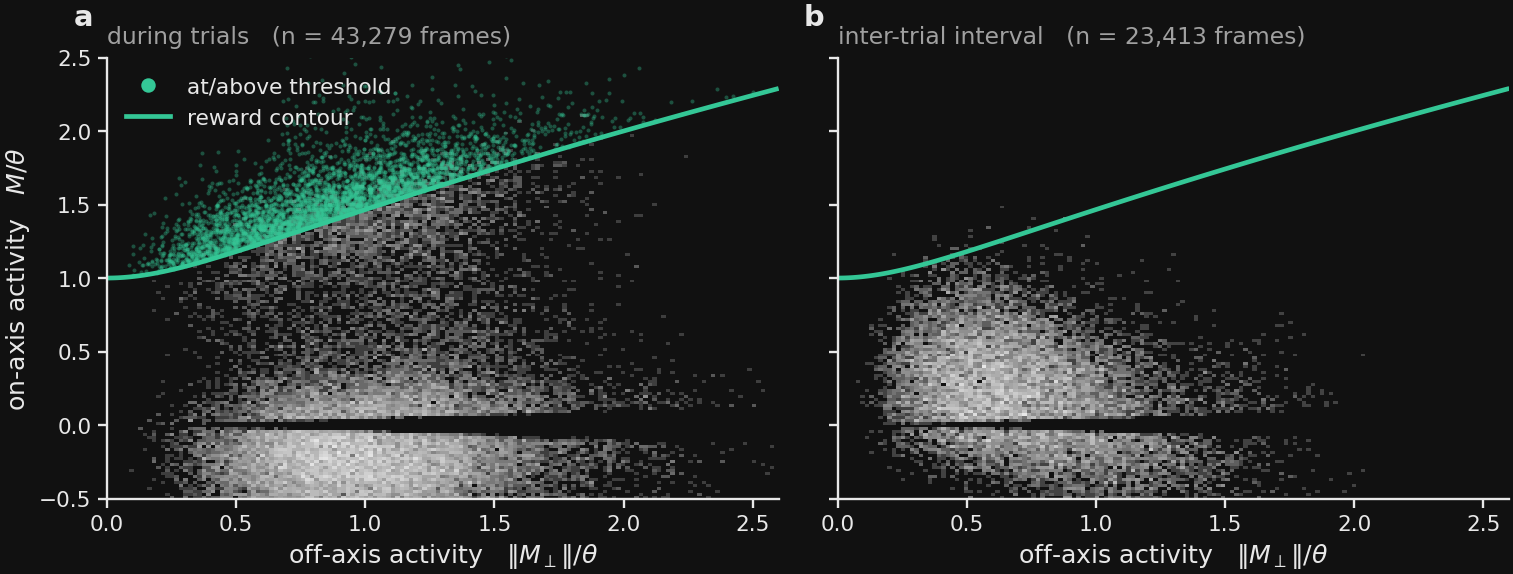

In [16]:
# ===== SETTINGS =====
FIGSIZE   = (12.0, 4.8)
BINS      = 150
X_MAX_OCC = 2.6               # ||M_perp|| / theta
Y_LIM_OCC = (-0.5, 2.5)       # M / theta
SHOW_CROSS = True             # mark the frames at or above the reward threshold
CROSS_MAX  = 4000             # subsample the crossing scatter so it stays readable
LW_THR_OCC = 2.6
TITLE     = None
SAVE_AS   = "fig2_occupancy"
# ============================================

m, mp = M / THR, MP / THR                      # same theta units as section 2.1
# Two masks that have to be chosen carefully. IN_EXP drops the 15% of frames from
# before and after the session. And "between trials" is the ITI epoch, NOT
# ~CE_trial -- that would swallow CE_rewardDelivery, where the cursor is at or
# above threshold by definition and would put 8% of "off-task" frames above the
# contour for a trivial reason.
in_trial = stage["CE_trial"] & usable & IN_EXP
off_task = stage["CE_ITI_withZ"] & usable & IN_EXP
xedges = np.linspace(0, X_MAX_OCC, BINS)
yedges = np.linspace(*Y_LIM_OCC, BINS)
Xo, Yo = np.meshgrid(np.linspace(0, X_MAX_OCC, 400), np.linspace(*Y_LIM_OCC, 400))
Zo = gated_field(Xo, Yo)

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, sharex=True, sharey=True)
for ax, sel, lab in [(axes[0], in_trial, "during trials"),
                     (axes[1], off_task, "inter-trial interval")]:
    H, xe, ye = np.histogram2d(mp[sel], m[sel], bins=[xedges, yedges])
    H = np.ma.masked_where(H == 0, H)
    ax.pcolormesh(xe, ye, H.T, cmap=INK_CMAP, norm=LogNorm(vmin=1, vmax=H.max()),
                  shading="auto", rasterized=True)
    ax.contour(Xo, Yo, Zo, levels=[1.0], colors=[P["correct"]], linewidths=LW_THR_OCC)
    ax.set_xlabel(r"off-axis activity   $\|M_\perp\|/\theta$")
    ax.set_title(f"{lab}   (n = {int(sel.sum()):,} frames)",
                 fontsize=13 * FONT_SCALE, color=P["muted"])
axes[0].set_ylabel(r"on-axis activity   $M/\theta$")

if SHOW_CROSS:
    idx = np.flatnonzero(at_thr)
    if idx.size > CROSS_MAX:
        idx = np.random.default_rng(0).choice(idx, CROSS_MAX, replace=False)
    axes[0].scatter(mp[idx], m[idx], s=5, c=P["correct"], alpha=0.35, lw=0,
                    rasterized=True, zorder=3)
    dw.legend_from(axes[0], [("at/above threshold", "marker", P["correct"], dict(ms=7)),
                             ("reward contour", "line", P["correct"], dict(lw=LW_THR_OCC))],
                   loc="upper left")

axes[0].set_xlim(0, X_MAX_OCC); axes[0].set_ylim(*Y_LIM_OCC)
for i, ax in enumerate(axes):
    dw.label_panel(ax, "ab"[i], color=P["fg"])
if TITLE:
    fig.suptitle(TITLE)
fig.tight_layout()
st.save_fig(fig, SAVE_AS);

# the angle of each frame's state from the decoder axis, then the median -- NOT the angle
# of the median state, which is meaningless here because M is negative half the time
print(f"median angle from the decoder axis: {np.median(ANG[in_trial]):.0f} deg during "
      f"trials, {np.median(ANG[at_thr]):.0f} deg at reward")
print(f"frames at or above the reward contour: {np.mean(D[in_trial] >= THR):.2%} "
      f"during trials, {np.mean(D[off_task] >= THR):.2%} in the ITI "
      f"({np.mean(D[in_trial] >= THR) / np.mean(D[off_task] >= THR):.1f}x)")

## 3 · From neurons to a tone

The whole chain on real data, one window of the session at a time.

The cell below prepares only the neuron panel: the activity matrix, and the decoder weight
each neuron carries on the active factor. Nothing downstream of it is reconstructed — `M`,
`CS`, the cursor and the tone all come straight out of the logger.

Two honest caveats about the neuron panel specifically. The packet stores `spks`
(OASIS-deconvolved), not the online dF/F the rig actually read, so it is the right neurons
but not bit-for-bit the signal the decoder saw. And the display applies a per-neuron
z-score plus a short **causal** exponential filter, which only stands in for the calcium
transient deconvolution removed; no information moves backwards in time.

In [6]:
# ---- the display transform for the neuron panel, written out ----
def zscore_rows(A):
    mu = np.nanmean(A, axis=1, keepdims=True)
    sd = np.nanstd(A, axis=1, keepdims=True)
    return (A - mu) / np.where(sd > 0, sd, 1.0)


def causal_exp_filter(A, tau_frames):
    # y[t] = a*y[t-1] + (1-a)*x[t]  -- one-sided, so no information moves backwards in
    # time. Written as an IIR filter so it runs in C rather than a 108k-step python loop.
    if tau_frames <= 0:
        return A
    a = np.exp(-1.0 / tau_frames)
    return lfilter([1.0 - a], [1.0, -a], A, axis=1)


TAU_FRAMES = 4.0          # validated range is 3-6; the curve is flat across it

Xn = np.asarray(na.load_neural(r, DAY), dtype=np.float32)[:, :NF]      # spks
W  = np.asarray(r["weights_day0_idxFactors"].load(), dtype=np.float64)
fac_col = int(np.nanmedian(np.asarray(ts["cursor_factor_to_use"], float))) - 1  # MATLAB -> py
wk = W[:, fac_col]                 # this day's decoder weight, one per neuron
have_w = np.isfinite(wk)           # the neurons the decoder actually reads
Xd = causal_exp_filter(zscore_rows(Xn), TAU_FRAMES)                    # display only

print(f"factor column {fac_col} (from cursor_factor_to_use = {fac_col + 1})")
print(f"{int(have_w.sum())}/{len(wk)} neurons carry a weight on this axis; "
      f"{np.mean(wk[have_w] > 0):.0%} of them positive, "
      f"weights {np.nanmin(wk):+.3f} .. {np.nanmax(wk):+.3f}")

factor column 1 (from cursor_factor_to_use = 2)
378/468 neurons carry a weight on this axis; 38% of them positive, weights -0.204 .. +0.292


### 3.1 · The chain, on one window of the session

Six rows, one moment, six representations — neurons at the top, the tone the mouse hears at
the bottom.

**The neuron panel is a heat map, not a spike raster.** Each row is one neuron, each column
one imaging frame, and the shade is that neuron's z-scored activity. Rows are **every neuron
the decoder reads** (no selection), sorted by decoder weight, split by the line where the
weight changes sign: the block above it pushes the cursor up, the block below pushes it
down. Set `N_NEURONS` to an integer to show only the largest-|weight| neurons instead.

Reading down the rows: `M` is the weighted sum of those neurons; the angle says how much of
the population state lies off the decoder axis; `cursor_brain` is `M` after the angle gate;
`freqToOutput` is that cursor turned into a pitch, which compresses the low end; and the
octave row is the same pitch on the scale the mouse hears it — **affine in the cursor**,
which is why the right-hand axis of that row can be labelled in `D/θ`.

**Colour marks the task state and nothing else.** Three states get a background —
quiescence, trial, reward tone — and every other frame gets none. A frame can satisfy more
than one (the cursor is often below the quiescence threshold *during* a trial), so each
frame is painted with exactly one, by the priority in the setup cell. The thresholds carry
the same colours as the states they gate: orange for quiescence, green for reward.

Choose the window with `START_TRIAL` or `START_MIN` in the setup cell — the length is
`WIN_SEC`.

In [1]:
# ===== SETTINGS =====
# the window comes from START_TRIAL / START_MIN / WIN_SEC in the setup cell;
# override here for this figure alone if you want a different one
WIN = dict(start_min=START_MIN, start_trial=START_TRIAL, win_sec=WIN_SEC)
N_NEURONS = 100          # None -> every weighted neuron; an int -> the top-|w| ones
FIGSIZE   = (15.0, 12.5)
HEIGHTS   = [1.8, 1.0, 0.9, 1.1, 1.0, 1.0]
SHOW_CS_GAPS = False      # band the frames where |CS| < CS_FLOOR; off by default,
                          # the breaks in the M trace already show them
VMAX_PCT  = 99.0          # clip the neuron heat map here, so a few bright frames
TITLE     = None          # do not wash the rest of it out
SAVE_AS   = "fig3_chain_v1"
# ============================================

f0, f1, ref, XLAB = pick_window(**WIN)
sl = slice(f0, f1)
t = (np.arange(f0, f1) - ref) / SR

fig, axes = plt.subplots(6, 1, figsize=FIGSIZE, sharex=True,
                         gridspec_kw=dict(height_ratios=HEIGHTS, hspace=0.14))

# --- row 1: the neurons the decoder reads, sorted by their weight ---
sel = np.flatnonzero(have_w)
if N_NEURONS:
    sel = sel[np.argsort(-np.abs(wk[sel]))][:int(N_NEURONS)]
order = sel[np.argsort(-wk[sel])]                     # most positive weight at the top
n_pos = int(np.sum(wk[order] > 0))
axes[0].imshow(Xd[order, sl], aspect="auto", cmap=INK_CMAP,
               extent=[t[0], t[-1], len(order), 0], interpolation="antialiased",
               vmin=0, vmax=np.nanpercentile(Xd[order, sl], VMAX_PCT))
axes[0].axhline(n_pos, color=P["fg"], lw=1.2)
axes[0].set_yticks([n_pos / 2, (n_pos + len(order)) / 2])
axes[0].set_yticklabels(["$w>0$", "$w<0$"], fontsize=11 * FONT_SCALE)
axes[0].set_ylabel(f"{len(order)} decoder neurons\n(sorted by weight)",
                   fontsize=12 * FONT_SCALE)

# --- row 2: the projection onto the decoder axis ---
axes[1].plot(t, M[sl], color=P["cursor"], lw=1.6)
axes[1].axhline(0.0, color=P["muted"], lw=0.8, ls=":")
axes[1].set_ylabel("$M$\n(on-axis)", fontsize=12 * FONT_SCALE)
if SHOW_CS_GAPS:
    dw.span_bands(axes[1], ~usable[sl], color=P["null"], alpha=0.30, sr=SR, t0=ref - f0,
                  zorder=0.5)

# --- row 3: how far off that axis the population state is ---
axes[2].plot(t, ANG[sl], color=P["cursor"], lw=1.6)
axes[2].set_ylim(0, 90); axes[2].set_yticks([0, 45, 90])
axes[2].set_ylabel("angle from\nthe axis (deg)", fontsize=12 * FONT_SCALE)

# --- row 4: the cursor. Two records: cursor_brain, and the cursor_output that the tone
# and the reward test actually follow. They agree except where the blue shows.
d_co = ~np.isclose(CB, CO, equal_nan=True)
axes[3].plot(t, CB[sl], color=P["cursor"], lw=1.8)
axes[3].plot(t, np.where(d_co[sl], CO[sl], np.nan), color=P["intuitive"], lw=1.8)
axes[3].axhline(THR, color=P["correct"], lw=1.6, ls="--")
axes[3].set_ylabel("cursor_brain\n$D$", fontsize=12 * FONT_SCALE)
axes[3].annotate(rf"reward  $\theta$={THR:g}", xy=(t[-1], THR), xytext=(-4, 4),
                 textcoords="offset points", color=P["correct"], ha="right",
                 va="bottom", fontsize=10.5 * FONT_SCALE)
if D_QUIESC is not None:
    axes[3].axhline(D_QUIESC, color=P["baseline"], lw=1.4, ls=":")
    axes[3].annotate(rf"quiescence gate  $M\leq{THR_QM:g}$", xy=(t[-1], D_QUIESC),
                     xytext=(-4, -4), textcoords="offset points", color=P["baseline"],
                     ha="right", va="top", fontsize=10.5 * FONT_SCALE)

# --- row 5: the pitch that was commanded, in Hz ---
ovr = stage["frequencyOverride"][sl]
axes[4].plot(t, np.where(ovr, np.nan, FRQ[sl]), color=P["cursor"], lw=1.6)
axes[4].plot(t, np.where(ovr, FRQ[sl], np.nan), color=P["correct"], lw=2.2)
axes[4].set_ylabel("freqToOutput\n(Hz)", fontsize=12 * FONT_SCALE)
axes[4].yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))

# --- row 6: the same pitch on the scale the animal hears it ---
axes[5].plot(t, np.where(ovr, np.nan, OCT[sl]), color=P["cursor"], lw=1.6)
axes[5].plot(t, np.where(ovr, OCT[sl], np.nan), color=P["correct"], lw=2.2)
axes[5].set_ylabel("tone\n(octaves re 1 kHz)", fontsize=12 * FONT_SCALE)
axes[5].set_xlabel(XLAB)
sec = axes[5].secondary_yaxis("right", functions=(oct_to_d, d_to_oct))
sec.set_ylabel("cursor_output  $D$", fontsize=12 * FONT_SCALE, color=P["muted"])
sec.tick_params(colors=P["muted"])

# --- the task state behind every row ---
for ax in axes:
    paint_states(ax, f0, ref, f1=f1)
    ax.set_xlim(t[0], t[-1])

_extra = []
if np.any(d_co[sl]):
    _extra.append(("cursor_output, where it differs", "line", P["intuitive"],
                   dict(lw=2.0)))
if SHOW_CS_GAPS:
    _extra.append(("|CS| too small to invert", "patch", P["null"], dict(alpha=0.30)))
state_legend(axes[0], _extra, loc="lower center", bbox_to_anchor=(0.5, 1.01),
             ncol=3 + len(_extra), fontsize=11 * FONT_SCALE)
if TITLE:
    fig.suptitle(TITLE)
st.save_fig(fig, SAVE_AS);

print(f"window: frames {f0}-{f1}  ({(f1 - f0) / SR:.0f} s, from {f0 / SR / 60:.1f} min)  "
      f"{int(np.sum((trials.start >= f0) & (trials.start < f1)))} trials start inside it")
print("state coverage: " + "  ".join(
    f"{k} {np.mean(STATE[sl] == i):.0%}" for i, k in enumerate(STATE_ORDER, start=1))
    + f"   no background {np.mean(STATE[sl] == 0):.0%}")
print(f"cursor_output differs from cursor_brain on {np.mean(d_co[sl] & IN_EXP[sl]):.1%} of "
      f"this window, {np.mean(d_co[IN_EXP]):.1%} of the session inside the experiment")

NameError: name 'START_MIN' is not defined

### 3.2 · The cursor→tone map, measured

The rig's configured parameters say `range_freqOutput = [1000, 18000]` Hz over
`bounds_cursor = [-1.5, 2.25]`. **Those numbers do not reproduce the tone that was played.**
What was actually played is exponential in the cursor expressed **as a fraction of that
animal's own reward threshold**:

$$\log_2 f = \log_2(2962.6) + 1.5669\,\frac{D}{\theta}, \qquad D/\theta \in [-1.0,\ +1.5]$$

Panel **a** shows the four animals in raw cursor units, where they lie on four different
lines because their thresholds differ (1.0 to 6.0). Panel **b** divides by each animal's
threshold and they collapse onto one. Panel **c** is a remapping day, where the two decoders
have *different* thresholds, so one session carries two pitch scales.

The tone at `D = θ` is 8777.2 Hz — exactly the constant the rig clamps to during reward. The
reward sound is the cursor frozen at the pitch it had to reach.

saved fig4_tone_map.pdf, fig4_tone_map.png


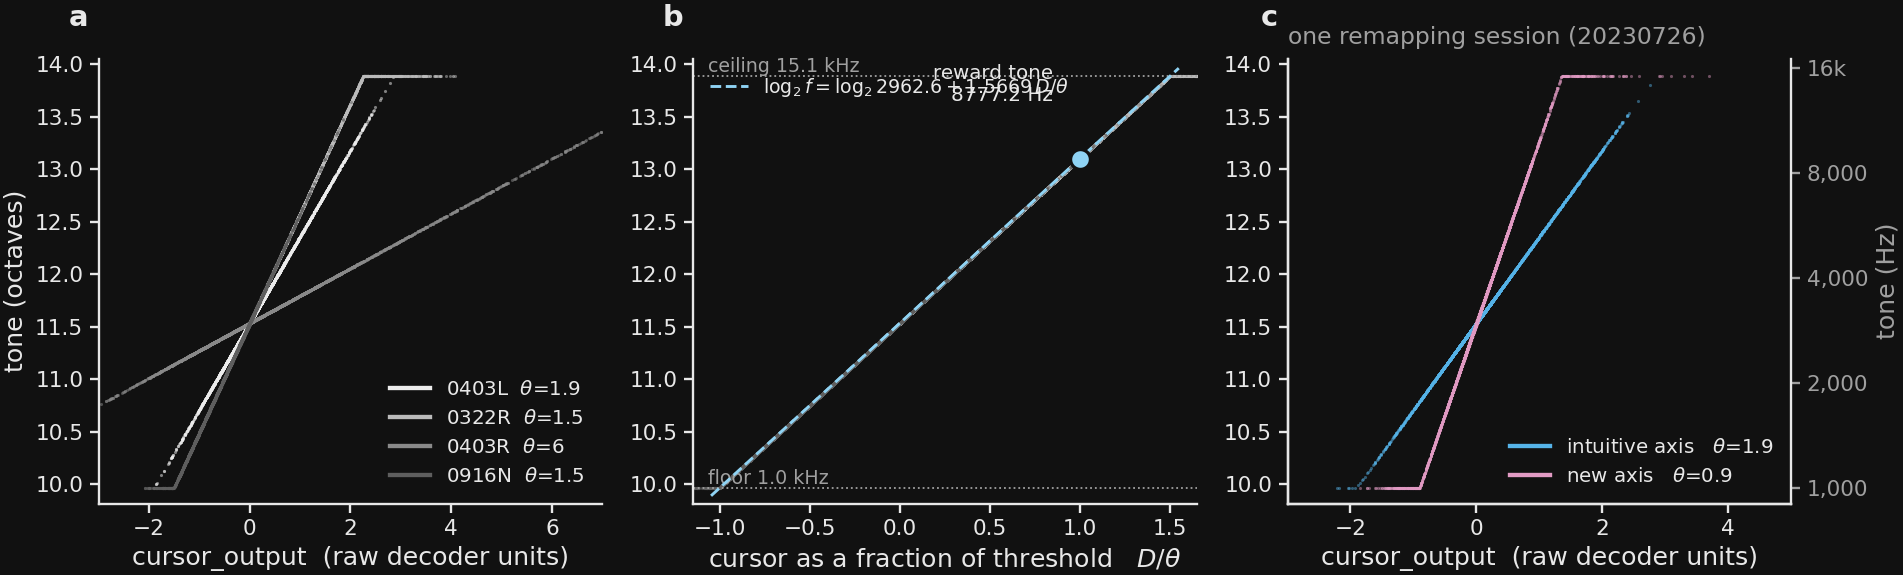

In [8]:
# ===== SETTINGS =====
FIGSIZE    = (15.0, 4.8)
MICE_ALL   = ["mouse_0403L", "mouse_0322R", "mouse_0403R", "mouse_0916N"]
DAY_PER_MOUSE = {"mouse_0403L": 8, "mouse_0322R": 2, "mouse_0403R": 2, "mouse_0916N": 1}
SUB_N      = 6000          # frames scattered per mouse
F_FLOOR, F_CEIL = 1000.0, 15107.6
F_REWARD   = 8777.2
TITLE      = None
SAVE_AS    = "fig4_tone_map"
# ============================================

def tone_points(mouse, day_i):
    rr = na.open_mouse(rfs, DATA_ROOT, mouse)
    dd = na.get_day_list(rr)[day_i]
    de, tsx = ca.get_decoder_df(rr, dd), ca.get_timeseries_df(rr, dd)
    n = min(len(de), len(tsx)); de, tsx = de.iloc[:n], tsx.iloc[:n]
    f = np.asarray(de["freqToOutput"], float)
    c = np.asarray(de["cursor_output"], float)
    o = np.asarray(tsx["frequencyOverride"], float) > 0.5
    th = np.asarray(tsx["cursor_threshold_reward"], float)
    fa = np.asarray(tsx["cursor_factor_to_use"], float)
    k = np.isfinite(f) & np.isfinite(c) & np.isfinite(th) & (~o) & (f > 0)
    return c[k], np.log2(f[k]), th[k], fa[k], dd

rng = np.random.default_rng(0)
greys = ["#1A1A1A", "#555555", "#8A8A8A", "#B9B9B9"] if THEME == "light" else \
        ["#EDEDED", "#BBBBBB", "#8A8A8A", "#5E5E5E"]

fig, axes = plt.subplots(1, 3, figsize=FIGSIZE)
for mi, mouse in enumerate(MICE_ALL):
    c, y, th, fa, dd = tone_points(mouse, DAY_PER_MOUSE[mouse])
    j = rng.choice(c.size, min(SUB_N, c.size), replace=False)
    lab = f"{mouse.replace('mouse_','')}  $\\theta$={np.nanmedian(th):g}"
    axes[0].scatter(c[j], y[j], s=3, c=greys[mi], alpha=0.5, lw=0, rasterized=True)
    axes[0].plot([], [], color=greys[mi], lw=2.4, label=lab)
    axes[1].scatter(c[j] / th[j], y[j], s=3, c=greys[mi], alpha=0.5, lw=0, rasterized=True)

axes[0].set_xlabel("cursor_output  (raw decoder units)")
axes[0].set_ylabel("tone (octaves)")
axes[0].set_xlim(-3, 7)
axes[0].legend(loc="lower right", fontsize=11 * FONT_SCALE)

# thin + dashed, so the four animals' scatter stays visible underneath: the point of
# this panel is that they collapse, which a fat line would simply hide
u = np.linspace(-1.05, 1.55, 200)
axes[1].plot(u, np.log2(2962.635) + 1.5669 * u, color=P["reward"], lw=1.6, ls="--",
             zorder=4, label=r"$\log_2 f = \log_2 2962.6 + 1.5669\,D/\theta$")
for v, lb in [(F_FLOOR, "floor 1.0 kHz"), (F_CEIL, "ceiling 15.1 kHz")]:
    axes[1].axhline(np.log2(v), color=P["muted"], lw=1.0, ls=":")
    axes[1].text(-1.1, np.log2(v), f" {lb}", fontsize=10.5 * FONT_SCALE,
                 color=P["muted"], va="bottom", ha="left")
axes[1].plot([1.0], [np.log2(F_REWARD)], "o", ms=11, mfc=P["reward"], mec=P["bg"], mew=1.8,
             zorder=5)
axes[1].annotate("reward tone\n8777.2 Hz", xy=(1.0, np.log2(F_REWARD)),
                 xytext=(0.85, np.log2(F_REWARD) + 0.55), fontsize=11 * FONT_SCALE,
                 color=P["fg"], ha="right")
axes[1].set_xlabel(r"cursor as a fraction of threshold   $D/\theta$")
axes[1].set_xlim(-1.15, 1.65)
axes[1].legend(loc="upper left", fontsize=10.5 * FONT_SCALE)

# --- panel c: a remapping day has two thresholds, so two scales ---
c, y, th, fa, dd_r = tone_points(MOUSE, REMAP_DAY_I)
for fv, key, lab in [(2.0, "intuitive", "intuitive axis"), (3.0, "new_axis", "new axis")]:
    k = fa == fv
    if k.sum() < 10:
        continue
    j = rng.choice(np.flatnonzero(k), min(SUB_N, int(k.sum())), replace=False)
    axes[2].scatter(c[j], y[j], s=3, c=P[key], alpha=0.45, lw=0, rasterized=True)
    axes[2].plot([], [], color=P[key], lw=2.4,
                 label=f"{lab}   $\\theta$={np.nanmedian(th[k]):g}")
axes[2].set_xlabel("cursor_output  (raw decoder units)")
axes[2].set_xlim(-3, 5)
axes[2].legend(loc="lower right", fontsize=11 * FONT_SCALE)
axes[2].set_title(f"one remapping session ({dd_r})", fontsize=13 * FONT_SCALE,
                  color=P["muted"])

for i, ax in enumerate(axes):
    ax.set_ylim(np.log2(900), np.log2(17000))
    if i == len(axes) - 1:
        dw.hz_axis(ax, color=P["muted"])
    dw.label_panel(ax, "abc"[i], color=P["fg"])
if TITLE:
    fig.suptitle(TITLE)
fig.tight_layout()
st.save_fig(fig, SAVE_AS);

### 3.3 · The gate that lets a trial start

The loop is not free-running: a new trial can only begin once the animal has held a
**quiescent** state for a short window. That is what carves the session into trials and
inter-trial periods, and it is why "baseline" is not simply "any time outside a trial".

**The gate is not the one the parameter names suggest.** The rig tests a conjunction —
`M ≤ thresh_quiescence_cursorMag` **and** `D ≤ thresh_quiescence_cursorDecoder` — and
`thresh_quiescence_cursorMag` is built as `max(10th percentile of M, 0)`, which comes out
as **exactly 0** on every day checked. Since `D = |CS|^p·M` always shares `M`'s sign, the
gate collapses to **`D ≤ 0`**: the animal has to push the population to the *negative* side
of the decoder axis, not merely be quiet. The `cursorDecoder` threshold (0.1 θ) is the
looser of the two and never binds. Reproduced to 100.000 % of frames on 0403L, 0403R and a
second 0403L day; one 0916N session disagrees and is flagged in the checks.

On the tone axis that boundary is **2963 Hz** — which is `f₀` of the cursor→tone law, the
pitch at cursor zero. So the quiescence gate is audible and simple: *the tone has to fall
back to its baseline pitch.*

Plotted on the tone axis, because that is the only part of this the animal can perceive.
The conversion is exact: the law of §3.2 is monotonic, and on this day no frame sits on the
1 kHz floor and 0.1 % on the ceiling.

Read `CS_quiescence` carefully — it is a **per-frame condition**, not an epoch and not "the
hold has been satisfied". Only about half its runs last long enough to arm a trial. That
split is the one thing a single background colour cannot show, so here quiescence moves to
its own strip under the trace with the two kinds drawn apart; the backgrounds keep only
trial and reward tone. The printout checks the claim the other way round: that a qualifying
hold really does precede a trial onset.

saved fig5_quiescence_gate.pdf, fig5_quiescence_gate.png
quiescence runs: n=3783, 50% reach the 3-frame hold (median run 3 frames)
last qualifying hold before a trial onset: median 3 frames (0.10 s); within 1 s for 82% of trials


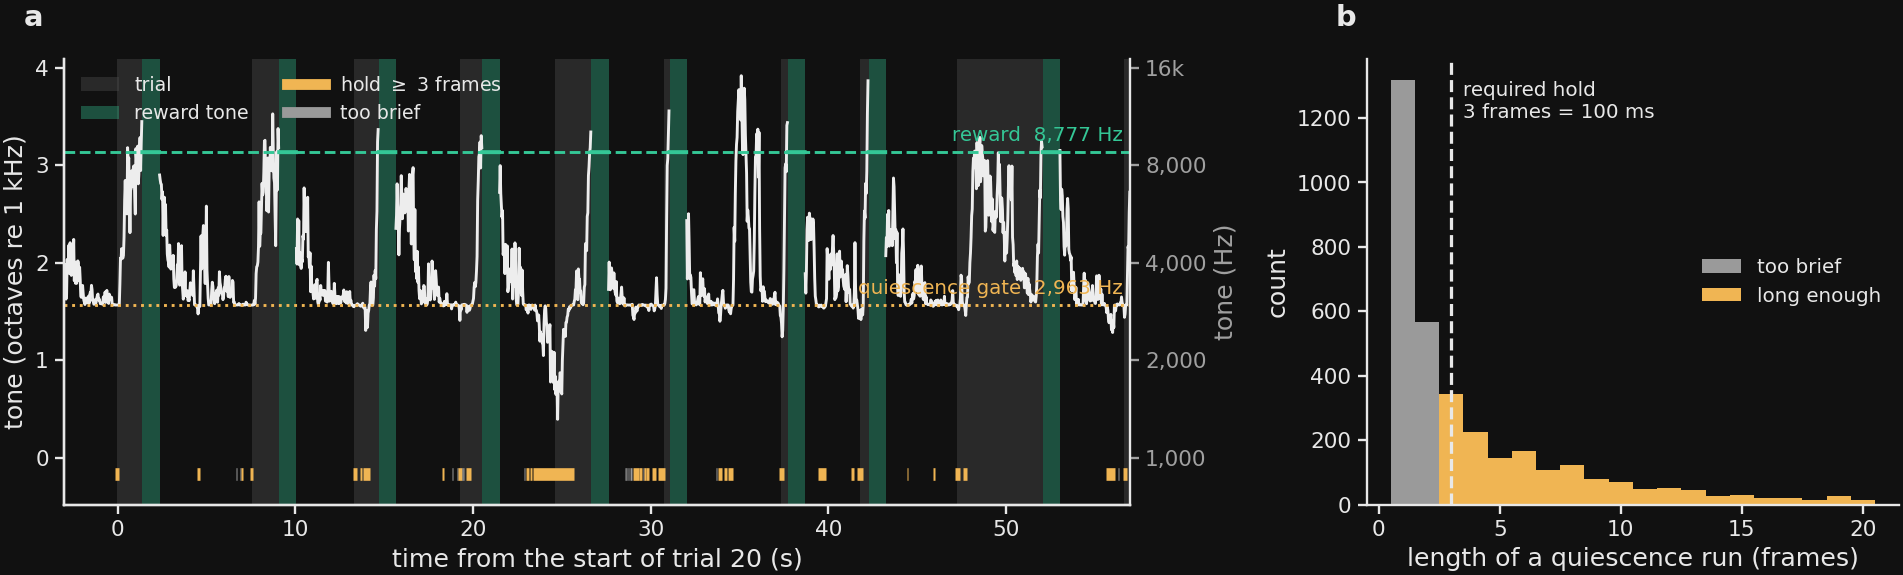

In [9]:
# ===== SETTINGS =====
WIN_Q      = dict(start_min=START_MIN, start_trial=START_TRIAL, win_sec=WIN_SEC)
FIGSIZE    = (15.0, 4.8)
HOLD_MAX_F = 20            # x-limit of the hold-duration histogram, in frames
TITLE      = None
SAVE_AS    = "fig5_quiescence_gate"
# ============================================

hold_req = float(par["trial"]["duration_quiescenceHold"])
q_runs = np.asarray(dw.runs(stage["CS_quiescence"]), int)
q_on, q_off = q_runs[:, 0], q_runs[:, 1]
hold = q_off - q_on
qualifies = hold >= hold_req

g0, g1, gref, GLAB = pick_window(**WIN_Q)
tg = (np.arange(g0, g1) - gref) / SR

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE,
                         gridspec_kw=dict(width_ratios=[2.0, 1.0]))

# --- a: the tone the mouse heard, with the gate visible ---
ax = axes[0]
paint_states(ax, g0, gref, keys=["trial", "reward tone"], f1=g1)
ovr_g = stage["frequencyOverride"][g0:g1]
ax.plot(tg, np.where(ovr_g, np.nan, OCT[g0:g1]), color=P["cursor"], lw=1.6)
ax.plot(tg, np.where(ovr_g, OCT[g0:g1], np.nan), color=P["correct"], lw=2.2)
for v, c, lb, ls in [(THR, P["correct"], "reward", "--"),
                     (D_QUIESC, P["baseline"], "quiescence gate", ":")]:
    if v is None:
        continue
    ax.axhline(d_to_oct(v), color=c, lw=1.6, ls=ls)
    ax.annotate(f"{lb}  {2 ** d_to_oct(v) * 1000:,.0f} Hz", xy=(tg[-1], d_to_oct(v)),
                xytext=(-4, 4), textcoords="offset points", color=c, va="bottom",
                ha="right", fontsize=11 * FONT_SCALE)

# the quiescence condition as its own strip, split into the two kinds
lo, hi = ax.get_ylim()
ax.set_ylim(lo - 0.18 * (hi - lo), hi)
y_strip = lo - 0.10 * (hi - lo)
for a_, b_, q_ in zip(q_on, q_off, qualifies):
    if b_ < g0 or a_ > g1:
        continue
    ax.plot([(max(a_, g0) - gref) / SR, (min(b_, g1) - gref) / SR], [y_strip] * 2,
            lw=7, solid_capstyle="butt",
            color=P["baseline"] if q_ else P["null"], zorder=3)
ax.set_xlabel(GLAB); ax.set_ylabel("tone (octaves re 1 kHz)")
ax.set_xlim(tg[0], tg[-1])
dw.hz_axis(ax, color=P["muted"], ref_hz=1000.0)
state_legend(ax, [(rf"hold $\geq$ {hold_req:g} frames", "line", P["baseline"],
                   dict(lw=6)),
                  ("too brief", "line", P["null"], dict(lw=6))],
             keys=["trial", "reward tone"], loc="upper left", ncol=2,
             fontsize=10.5 * FONT_SCALE)

# --- b: most dips are too brief to arm a trial ---
ax = axes[1]
bins = np.arange(0.5, HOLD_MAX_F + 1.5)
ax.hist(hold[~qualifies & (hold <= HOLD_MAX_F)], bins=bins, color=P["null"], lw=0,
        label="too brief")
ax.hist(hold[qualifies & (hold <= HOLD_MAX_F)], bins=bins, color=P["baseline"], lw=0,
        label="long enough")
ax.axvline(hold_req, color=P["fg"], lw=1.8, ls="--")
ax.text(hold_req + 0.5, ax.get_ylim()[1] * 0.95,
        f"required hold\n{hold_req:g} frames = {hold_req / SR * 1000:.0f} ms",
        fontsize=11 * FONT_SCALE, color=P["fg"], va="top")
ax.set_xlabel("length of a quiescence run (frames)"); ax.set_ylabel("count")
ax.legend(loc="center right", fontsize=11 * FONT_SCALE)

for i, ax in enumerate(axes):
    dw.label_panel(ax, "ab"[i], color=P["fg"])
if TITLE:
    fig.suptitle(TITLE)
fig.tight_layout()
st.save_fig(fig, SAVE_AS);

# --- the gate claim, tested the other way round ---
ce_on = np.array([a for a, _ in dw.runs(stage["CE_trial"])])
gap = np.array([s - q_on[qualifies][q_on[qualifies] <= s][-1]
                for s in ce_on if np.any(q_on[qualifies] <= s)])
print(f"quiescence runs: n={hold.size}, {qualifies.mean():.0%} reach the "
      f"{hold_req:g}-frame hold (median run {np.median(hold):.0f} frames)")
print(f"last qualifying hold before a trial onset: median {np.median(gap):.0f} frames "
      f"({np.median(gap) / SR:.2f} s); within 1 s for {np.mean(gap <= SR):.0%} of trials")

### 3.4 · Commanded tone vs what the speaker did

`freqToOutput` is the software command; `data_ws["cursor"]` is the analog readback of the
signal that actually drove the speaker. They are not the same record, and the loop's
physical latency shows up as a one-frame offset between them.

The readback is an uncalibrated voltage, so it gets its own right-hand axis in arbitrary
units — only its **timing** is being claimed here, not its scale. The command keeps the Hz
axis it is logged in.

This is also the one place a dB axis would belong, and the one place it cannot be drawn:
`soundVolume` is binary (a gate, 83–100 % on during trials), and the packet carries no
speaker calibration. Level is unknown; pitch is exact.

saved fig6_command_vs_played.pdf, fig6_command_vs_played.png
readback follows the command by 1 frame(s) = 33 ms, r = 0.962   (whole session, n = 91,864 frames)


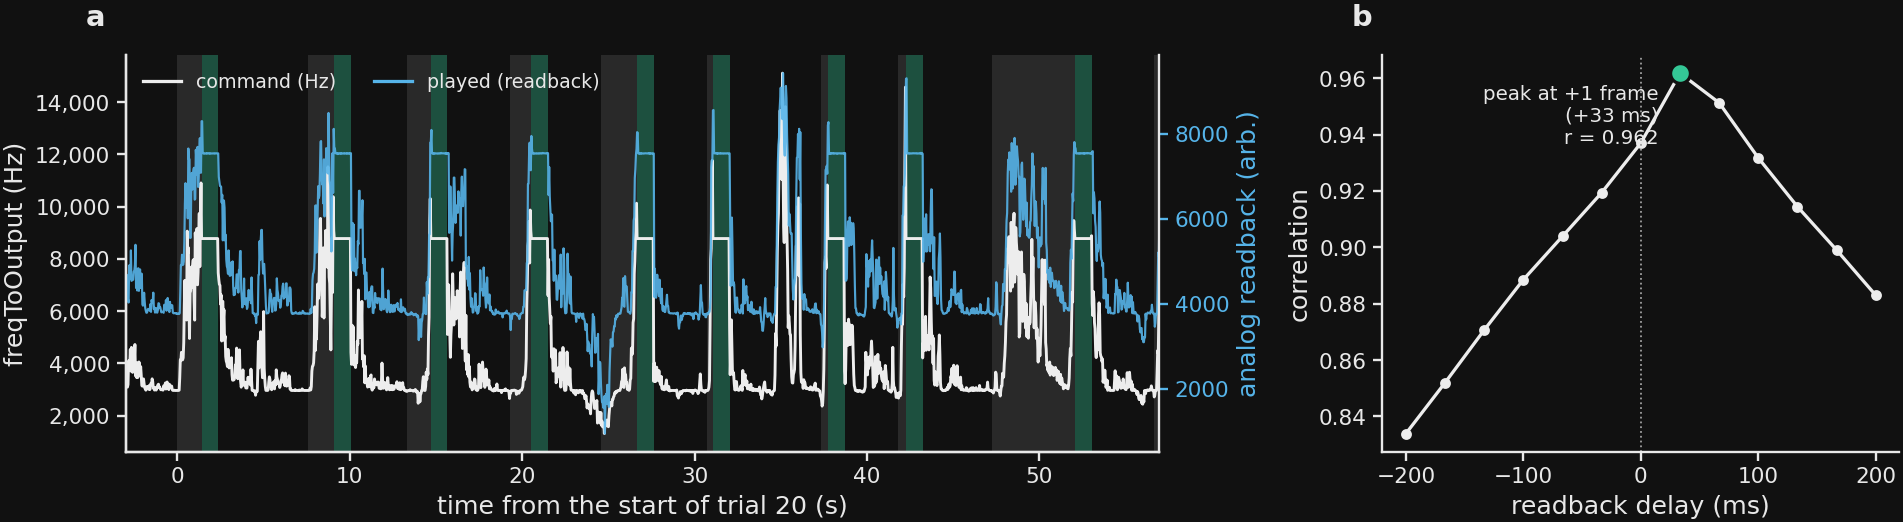

In [10]:
# ===== SETTINGS =====
WIN_W     = dict(start_min=START_MIN, start_trial=START_TRIAL, win_sec=WIN_SEC)
FIGSIZE   = (15.0, 4.4)
LAGS      = np.arange(-6, 7)
TITLE     = None
SAVE_AS   = "fig6_command_vs_played"
# ============================================

ws = np.asarray(na.load_cursor(r, DAY), float)[:NF]
k = np.isfinite(FRQ) & np.isfinite(ws)
az = (FRQ - np.nanmean(FRQ[k])) / np.nanstd(FRQ[k])
bz = (ws - np.nanmean(ws[k])) / np.nanstd(ws[k])
# LAGS is the delay OF THE READBACK: at lag L we compare the command at time t with the
# readback at t+L, so a positive peak means the speaker followed the command, as it must.
cc = []
for L in LAGS:
    cmd = az[max(0, -L): NF - max(0, L)]
    play = bz[max(0, L): NF - max(0, -L)]
    kk = np.isfinite(cmd) & np.isfinite(play)
    cc.append(np.corrcoef(cmd[kk], play[kk])[0, 1])
cc = np.asarray(cc); best = LAGS[np.argmax(cc)]

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE,
                         gridspec_kw=dict(width_ratios=[2.0, 1.0]))

# --- a: the two records over the same window, each on its own scale ---
h0, h1, href, HLAB = pick_window(**WIN_W)
th_ = (np.arange(h0, h1) - href) / SR
ax = axes[0]
paint_states(ax, h0, href, keys=["trial", "reward tone"], f1=h1)
ax.plot(th_, FRQ[h0:h1], color=P["cursor"], lw=1.6)
ax.set_ylabel("freqToOutput (Hz)")
ax.yaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel(HLAB); ax.set_xlim(th_[0], th_[-1])
tw = ax.twinx()
tw.plot(th_, ws[h0:h1], color=P["intuitive"], lw=1.2, alpha=0.9)
tw.set_ylabel("analog readback (arb.)", color=P["intuitive"])
tw.tick_params(colors=P["intuitive"])
tw.spines["right"].set_visible(True)
dw.legend_from(ax, [("command (Hz)", "line", P["cursor"], dict(lw=1.8)),
                    ("played (readback)", "line", P["intuitive"], dict(lw=1.8))],
               loc="upper left", ncol=2, fontsize=10.5 * FONT_SCALE)

# --- b: the whole session's cross-correlation, where the latency actually shows ---
ax = axes[1]
ax.plot(LAGS / SR * 1000, cc, "-o", color=P["cursor"], ms=5)
ax.plot([best / SR * 1000], [cc.max()], "o", ms=11, mfc=P["correct"], mec=P["bg"],
        mew=1.8, zorder=5)
ax.annotate(f"peak at {best:+d} frame\n({best / SR * 1000:+.0f} ms)\nr = {cc.max():.3f}",
            xy=(best / SR * 1000, cc.max()), xytext=(-12, -6),
            textcoords="offset points", ha="right", va="top",
            fontsize=11 * FONT_SCALE, color=P["fg"])
ax.axvline(0, color=P["muted"], lw=1.0, ls=":")
ax.set_xlabel("readback delay (ms)")
ax.set_ylabel("correlation")

for i, a in enumerate(axes):
    dw.label_panel(a, "ab"[i], color=P["fg"])
if TITLE:
    fig.suptitle(TITLE)
fig.tight_layout()
st.save_fig(fig, SAVE_AS);
print(f"readback follows the command by {best} frame(s) = {best / SR * 1000:.0f} ms, "
      f"r = {cc.max():.3f}   (whole session, n = {int(k.sum()):,} frames)")

## 4 · Checks

Everything the figures above assert, re-derived and asserted numerically. A FAIL here means
a figure is wrong, not that a parameter drifted.

In [11]:
checks = []
def chk(name, cond, detail=""):
    checks.append((bool(cond), name, detail))

# ---- the geometry ----
chk("gate inversion round-trips to machine precision", RT_ERR < 1e-10, f"max err {RT_ERR:.1e}")
chk("cursor_brain == cursor_brain_raw (win_smooth_cursor = 1)",
    np.allclose(CB[usable], D[usable]), "")
chk("p = 2 on this day", POW == 2.0, f"p={POW}")
chk("threshold read from timeSeries, not params",
    THR != float(par['cursor']['threshold_reward']),
    f"timeSeries {THR:g} vs params {par['cursor']['threshold_reward']:g}")
chk("a 50/50 mix needs exactly 2x the projection",
    abs(((2*THR)**3 / ((2*THR)**2 + (2*THR)**2)) - THR) < 1e-12, "")
chk("measured state at reward is off-axis", M_AT > THR,
    f"M={M_AT:.2f} vs theta={THR:g} ({M_AT/THR - 1:+.0%})")

# ---- which cursor record drives what ----
_pred_co = np.log2(TONE_F0) + TONE_SLOPE * (CO / THR)
_pred_cb = np.log2(TONE_F0) + TONE_SLOPE * (CB / THR)
_lg = np.log2(FRQ)
_sat = (FRQ <= 1000.5) | (FRQ >= 15107.0)
_ok = np.isfinite(_lg) & (~stage['frequencyOverride']) & (~_sat)
_hit_co = float(np.mean(np.abs(_pred_co[_ok] - _lg[_ok]) < 1e-3))
_hit_cb = float(np.mean(np.abs(_pred_cb[_ok] - _lg[_ok]) < 1e-3))
chk("the tone follows cursor_output, not cursor_brain", _hit_co > 0.999 and _hit_cb < _hit_co,
    f"cursor_output {_hit_co:.2%} vs cursor_brain {_hit_cb:.2%} of {int(_ok.sum()):,} frames")
chk("the reward condition is tested on cursor_output",
    np.mean((CO >= THR) == stage['CS_threshold'])
    > np.mean((CB >= THR) == stage['CS_threshold']),
    f"cursor_output {np.mean((CO >= THR) == stage['CS_threshold']):.3%} vs cursor_brain "
    f"{np.mean((CB >= THR) == stage['CS_threshold']):.3%}")

# ---- the tone law ----
chk("tone law predicts the reward tone",
    abs(2 ** (np.log2(TONE_F0) + TONE_SLOPE) - 8777.2) < 5.0,
    f"predicted {2 ** (np.log2(TONE_F0) + TONE_SLOPE):.1f} Hz vs clamped 8777.2 Hz")
_f = FRQ[~stage['frequencyOverride'] & np.isfinite(FRQ)]
chk("tone stays inside the measured floor/ceiling",
    (_f.min() >= 999.0) and (_f.max() <= 15108.0), f"{_f.min():.0f}-{_f.max():.0f} Hz")
_k = (np.isfinite(CO) & np.isfinite(FRQ) & (~stage['frequencyOverride'])
      & (FRQ > 1001) & (FRQ < 15100))
_s, _i = np.polyfit(CO[_k], np.log2(FRQ[_k]), 1)
_r2 = 1 - (np.log2(FRQ[_k]) - (_s * CO[_k] + _i)).var() / np.log2(FRQ[_k]).var()
chk("tone law fits this day exactly", _r2 > 0.999,
    f"R2={_r2:.6f}, f0={2 ** _i:.1f} Hz (expect {TONE_F0:.1f})")
chk("tone scale is anchored to this animal's threshold", abs(_s * THR - TONE_SLOPE) < 0.01,
    f"slope x theta = {_s * THR:.4f} (expect {TONE_SLOPE})")
chk("soundVolume is binary (a gate, so no dB axis exists)",
    set(np.unique(VOL[np.isfinite(VOL)])) <= {0.0, 1.0}, "")
chk("reward override is a single constant tone",
    np.unique(np.round(FRQ[stage['frequencyOverride'] & np.isfinite(FRQ)], 1)).size == 1, "")

# ---- the task flags ----
chk("the quiescence gate is the M term, not the cursorDecoder threshold",
    CSQ_AGREE > 0.999 and THR_QM == 0.0,
    f"(M <= {THR_QM:g}) & (D <= {THR_Q:g}) reproduces CS_quiescence on {CSQ_AGREE:.3%}; "
    f"D <= {THR_Q:g} alone would give {np.mean((D <= THR_Q) == stage['CS_quiescence']):.1%}")
chk("CS_quiescence never holds with a positive cursor",
    not np.any(stage['CS_quiescence'] & (D > 0)),
    f"{int(np.sum(stage['CS_quiescence'] & (D > 0)))} frames")
chk("CE_experimentRunning is an umbrella flag, not an epoch",
    IN_EXP.mean() > 0.5 and np.all(IN_EXP[stage['CE_trial']]),
    f"covers {IN_EXP.mean():.1%} of frames and every CE_trial frame")
chk("conditions really do overlap the epochs, so states need a priority",
    np.mean(stage['CS_quiescence'] & stage['CE_trial']) > 0.01,
    f"CS_quiescence is true inside CE_trial on "
    f"{np.mean(stage['CS_quiescence'][stage['CE_trial']]):.1%} of trial frames")
chk("every frame gets at most one background state",
    STATE.min() >= 0 and STATE.max() == len(STATE_ORDER), f"states 0..{STATE.max()}")
_ce_on = np.array([a for a, _ in dw.runs(stage['CE_trial'])])
_d = np.array([_ce_on[np.argmin(np.abs(_ce_on - s))] - s
               for s in np.asarray(trials.start, float) if np.isfinite(s)])
chk("trials.start agrees with the CE_trial epoch onset", np.mean(np.abs(_d) <= 1) > 0.99,
    f"|offset| <= 1 frame on {np.mean(np.abs(_d) <= 1):.1%} of trials "
    f"(median {np.median(_d):+.0f}, the MATLAB 1-index)")
chk("threshold hold is short (tens of ms, not seconds)",
    np.median([b - a for a, b in dw.runs(stage['CS_threshold'])]) <= 5,
    f"median {np.median([b - a for a, b in dw.runs(stage['CS_threshold'])]):.0f} frames")

# ---- the loop and the window chooser ----
chk("analog readback follows the command by ~1 frame", best in (1, 2),
    f"delay={best} frames = {best / SR * 1000:.0f} ms")
_w0, _w1, _wr, _ = pick_window(start_trial=0)
chk("every window is at least WIN_SEC long", (_w1 - _w0) / SR >= WIN_SEC - 1e-9,
    f"{(_w1 - _w0) / SR:.0f} s")
try:
    pick_window(start_min=1.0, start_trial=1); _both = False
except ValueError:
    _both = True
chk("pick_window refuses START_MIN and START_TRIAL together", _both, "")

n_ok = sum(c[0] for c in checks)
for ok_, name, det in checks:
    print(f"{'PASS' if ok_ else 'FAIL'}  {name}" + (f"   [{det}]" if det else ""))
print(f"\n{n_ok}/{len(checks)} checks pass")

PASS  gate inversion round-trips to machine precision   [max err 8.9e-16]
PASS  cursor_brain == cursor_brain_raw (win_smooth_cursor = 1)
PASS  p = 2 on this day   [p=2.0]
PASS  threshold read from timeSeries, not params   [timeSeries 1.9 vs params 1.5]
PASS  a 50/50 mix needs exactly 2x the projection
PASS  measured state at reward is off-axis   [M=2.92 vs theta=1.9 (+54%)]
PASS  the tone follows cursor_output, not cursor_brain   [cursor_output 100.00% vs cursor_brain 92.20% of 84,540 frames]
PASS  the reward condition is tested on cursor_output   [cursor_output 100.000% vs cursor_brain 99.789%]
PASS  tone law predicts the reward tone   [predicted 8777.3 Hz vs clamped 8777.2 Hz]
PASS  tone stays inside the measured floor/ceiling   [1000-15108 Hz]
PASS  tone law fits this day exactly   [R2=1.000000, f0=2962.6 Hz (expect 2962.6)]
PASS  tone scale is anchored to this animal's threshold   [slope x theta = 1.5669 (expect 1.5669)]
PASS  soundVolume is binary (a gate, so no dB axis exists)
PA